In [2]:
#qt for gui figures, inline for embedded in notebook 
%matplotlib qt
%matplotlib inline 
import hyperspy.api as hs
import exspy
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
s = hs.load("SRM621_0p078.rpl", stack=True)
s.set_signal_type("EDS_SEM")
s.metadata.General.title = '621'
s

  0%|          | 0/1 [00:00<?, ?it/s]

<EDSSEMSpectrum, title: 621, dimensions: (1024, 768|2508)>

In [4]:
s.axes_manager.gui()
#enter pixel, and -0.96 offset keV and 0.01 keV, scale is 0.078 microns

The inline matplotlib backend is not compatible with the traitsui GUI elements. For more information, read https://hyperspy.readthedocs.io/en/stable/user_guide/basic_usage.html#possible-warnings-when-importing-hyperspy.


/Users/thomaslam/anaconda3/lib/python3.13/site-packages/rsciio/utils/rgb_tools.py:62: VisibleDeprecationWarning: The module `rsciio.utils.rgb_tools` has been renamed to `rsciio.utils.rgb` and it will be removed in version 1.0.
  warnings.warn(


(0.2, 7.0)

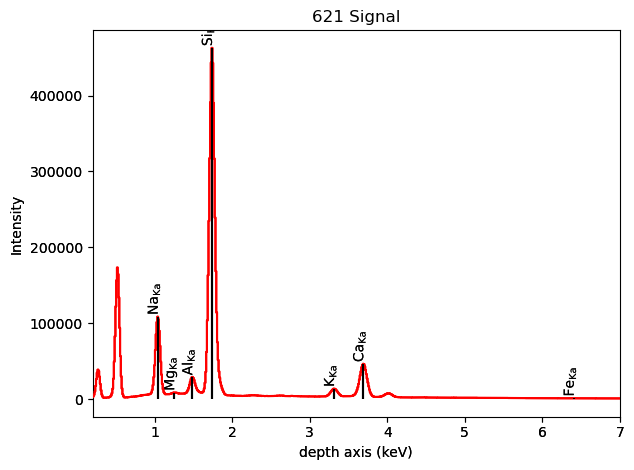

In [5]:
sum_spec = s.sum()
sum_spec.set_elements(["Na", "Mg", "Al", "Si", "K", "Ca", "Fe"])
sum_spec.add_lines(["Na_Ka", "Mg_Ka", "Al_Ka", "Si_Ka", "K_Ka", "Ca_Ka", "Fe_Ka"])
sum_spec.plot(True)
sum_spec._plot.signal_plot.ax.set_xlim(0.2, 7)

In [6]:
#Na background and net counts calc
ss = sum_spec
x = ss.axes_manager.signal_axes[0].axis
y = ss.data

left_bg = (x >= 0.84) & (x <= 0.90)
right_bg = (x >= 1.16) & (x <= 1.22)
peak = (x >= 0.96) & (x <= 1.12)

x_bg = np.r_[x[left_bg], x[right_bg]]
y_bg = np.r_[y[left_bg], y[right_bg]]

coef = np.polyfit(x_bg, y_bg, 1)
baseline = np.polyval(coef, x)

y_corr = y - baseline
Na_net = y_corr[peak].sum()
print("Na_net_counts", f"{Na_net:.3f}")

#Na2O Quant
df = pd.read_csv("15kV_Stds_Lib.csv")
net_counts_Na_stds = pd.to_numeric(df.iloc[0, 1], errors="raise")
K_ratio_Na = Na_net/net_counts_Na_stds
print ("K_ratio_Na", f"{K_ratio_Na:.3f}")

df = pd.read_csv("15kV_Stds_Lib.csv")
Lookup_Na2O = pd.to_numeric(df.iloc[2, 1], errors="raise")
mass_percent_Na2O = K_ratio_Na * Lookup_Na2O
print("mass_percent_Na2O", f"{mass_percent_Na2O:.3f}")

#MgO background and net counts calc
ss = sum_spec
x = ss.axes_manager.signal_axes[0].axis
y = ss.data

left_bg = (x >= 1.16) & (x <= 1.18)
right_bg = (x >= 1.34) & (x <= 1.36)
peak = (x >= 1.2) & (x <= 1.32)

x_bg = np.r_[x[left_bg], x[right_bg]]
y_bg = np.r_[y[left_bg], y[right_bg]]

coef = np.polyfit(x_bg, y_bg, 1)
baseline = np.polyval(coef, x)

y_corr = y - baseline
Mg_net = y_corr[peak].sum()
print("Mg_net_counts", f"{Mg_net:.3f}")

#MgO Quant
df = pd.read_csv("15kV_Stds_Lib.csv")
net_counts_Mg_stds = pd.to_numeric(df.iloc[0, 2], errors="raise")
K_ratio_Mg = Mg_net/net_counts_Mg_stds
print ("K_ratio_Mg", f"{K_ratio_Mg:.3f}")

df = pd.read_csv("15kV_Stds_Lib.csv")
Lookup_MgO = pd.to_numeric(df.iloc[2, 2], errors="raise")
mass_percent_MgO = K_ratio_Mg * Lookup_MgO
print("mass_percent_MgO", f"{mass_percent_MgO:.3f}")

#Al background and net counts calc
ss = sum_spec
x = ss.axes_manager.signal_axes[0].axis
y = ss.data

left_bg = (x >= 1.32) & (x <= 1.36)
right_bg = (x >= 1.58) & (x <= 1.62)
peak = (x >= 1.4) & (x <= 1.55)

x_bg = np.r_[x[left_bg], x[right_bg]]
y_bg = np.r_[y[left_bg], y[right_bg]]

coef = np.polyfit(x_bg, y_bg, 1)
baseline = np.polyval(coef, x)

y_corr = y - baseline
Al_net = y_corr[peak].sum()
print("Al_net_counts", f"{Al_net:.3f}")

#Al2O3 Quant
df = pd.read_csv("15kV_Stds_Lib.csv")
net_counts_Al_stds = pd.to_numeric(df.iloc[0, 3], errors="raise")
K_ratio_Al = Al_net/net_counts_Al_stds
print ("K_ratio_Al", f"{K_ratio_Al:.3f}")

df = pd.read_csv("15kV_Stds_Lib.csv")
Lookup_Al2O3 = pd.to_numeric(df.iloc[2, 3], errors="raise")
mass_percent_Al2O3 = K_ratio_Al * Lookup_Al2O3
print("mass_percent_Al2O3", f"{mass_percent_Al2O3:.3f}")

#Si background and net counts calc
ss = sum_spec
x = ss.axes_manager.signal_axes[0].axis
y = ss.data

left_bg = (x >= 1.58) & (x <= 1.62)
right_bg = (x >= 1.9) & (x <= 1.95)
peak = (x >= 1.66) & (x <= 1.84)

x_bg = np.r_[x[left_bg], x[right_bg]]
y_bg = np.r_[y[left_bg], y[right_bg]]

coef = np.polyfit(x_bg, y_bg, 1)
baseline = np.polyval(coef, x)

y_corr = y - baseline
Si_net = y_corr[peak].sum()
print("Si_net_counts", f"{Si_net:.3f}")

#SiO2 Quant
df = pd.read_csv("15kV_Stds_Lib.csv")
net_counts_Si_stds = pd.to_numeric(df.iloc[0, 4], errors="raise")
K_ratio_Si = Si_net/net_counts_Si_stds
print ("K_ratio_Si", f"{K_ratio_Si:.3f}")

df = pd.read_csv("15kV_Stds_Lib.csv")
Lookup_SiO2 = pd.to_numeric(df.iloc[2, 4], errors="raise")
mass_percent_SiO2 = K_ratio_Si * Lookup_SiO2
print("mass_percent", f"{mass_percent_SiO2:.3f}")

#K background and net counts calc
ss = sum_spec
x = ss.axes_manager.signal_axes[0].axis
y = ss.data

left_bg = (x >= 3.0) & (x <= 3.1)
right_bg = (x >= 3.48) & (x <= 3.52)
peak = (x >= 3.2) & (x <= 3.42)

x_bg = np.r_[x[left_bg], x[right_bg]]
y_bg = np.r_[y[left_bg], y[right_bg]]

coef = np.polyfit(x_bg, y_bg, 1)
baseline = np.polyval(coef, x)

y_corr = y - baseline
K_net = y_corr[peak].sum()
print("K_net_counts", f"{K_net:.3f}")

#K2O Quant
df = pd.read_csv("15kV_Stds_Lib.csv")
net_counts_K_stds = pd.to_numeric(df.iloc[0, 7], errors="raise")
K_ratio_K = K_net/net_counts_K_stds
print ("K_ratio_K", f"{K_ratio_K:.3f}")

df = pd.read_csv("15kV_Stds_Lib.csv")
Lookup_K2O = pd.to_numeric(df.iloc[2, 7], errors="raise")
mass_percent_K2O = K_ratio_K * Lookup_K2O
print("mass_percent_K2O", f"{mass_percent_K2O:.3f}")

#Ca background and net counts calc
ss = sum_spec
x = ss.axes_manager.signal_axes[0].axis
y = ss.data

left_bg = (x >= 3.44) & (x <= 3.5)
right_bg = (x >= 3.82) & (x <= 3.88)
peak = (x >= 3.59) & (x <= 3.82)

x_bg = np.r_[x[left_bg], x[right_bg]]
y_bg = np.r_[y[left_bg], y[right_bg]]

coef = np.polyfit(x_bg, y_bg, 1)
baseline = np.polyval(coef, x)

y_corr = y - baseline
Ca_net = y_corr[peak].sum()
print("Ca_net_counts", f"{Ca_net:.3f}")

#CaO Quant
df = pd.read_csv("15kV_Stds_Lib.csv")
net_counts_Ca_stds = pd.to_numeric(df.iloc[0, 8], errors="raise")
K_ratio_Ca = Ca_net/net_counts_Ca_stds
print ("K_ratio_Ca", f"{K_ratio_Ca:.3f}")

df = pd.read_csv("15kV_Stds_Lib.csv")
Lookup_CaO = pd.to_numeric(df.iloc[2, 8], errors="raise")
mass_percent_CaO = K_ratio_Ca * Lookup_CaO
print("mass_percent_CaO", f"{mass_percent_CaO:.3f}")


Na_net_counts 759215.914
K_ratio_Na 0.999
mass_percent_Na2O 11.614
Mg_net_counts 13743.245
K_ratio_Mg 0.004
mass_percent_MgO 0.207
Al_net_counts 164360.000
K_ratio_Al 0.159
mass_percent_Al2O3 2.654
Si_net_counts 3913445.755
K_ratio_Si 1.128
mass_percent 73.129
K_net_counts 104130.787
K_ratio_K 0.118
mass_percent_K2O 1.835
Ca_net_counts 479206.436
K_ratio_Ca 0.213
mass_percent_CaO 10.267


In [7]:
# Export of Quant

out = pd.DataFrame([
    ["Na", K_ratio_Na, mass_percent_Na2O],
    ["Mg", K_ratio_Mg, mass_percent_MgO],
    ["Al", K_ratio_Al, mass_percent_Al2O3],
    ["Si", K_ratio_Si, mass_percent_SiO2],
    ["K", K_ratio_K, mass_percent_K2O],
    ["Ca", K_ratio_Ca, mass_percent_CaO]
], columns=["Element", "K_ratio", "Oxide_quant_pct"])

out = out.round(2)
out.to_csv("SRM621_Quant.csv", index=False)